# Bonus: pronóstico de dengue por provincia con SimpleRNN

El enunciado propone como **bonus** la predicción por provincia con `vectoria_dengue_semanal.csv`. Igual que en el notebook 03, con el clima y los casos de las últimas 26 semanas se pronostican los casos de las próximas 4 semanas, pero ahora para cada una de las 7 provincias.

> **Aviso:** estos datos son **sintéticos**. Los generó el paquete del curso (`generar_sintetico.py`, semilla 42) y **no son cifras oficiales**. Un buen resultado aquí indica que la red aprende los patrones que tiene el generador, no que pronostique el dengue real de cada provincia. El pronóstico nacional con datos reales sigue siendo el del notebook 03.

Usa la misma red base del notebook 03 (`crear_simplernn` de `src/train/lstm.py`: SimpleRNN(32) → Dense(4)), el mismo tipo de split, las mismas métricas y los mismos dos controles (baseline estacional y persistencia).

**No visto en clase:** un solo modelo para varias series (las 7 provincias juntas), la provincia como variable *one-hot* y las ventanas armadas con un ciclo en vez de `TimeseriesGenerator`, porque el generador corta una sola serie y aquí hay 7.

# 1. Importación librerías

In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"   # para que los resultados se puedan repetir

import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

tf.get_logger().setLevel("ERROR")   # oculta avisos internos de TensorFlow

sys.path.append("..")   # para usar la misma red del notebook 03 (src/train/lstm.py)
from src.train.lstm import crear_simplernn, VENTANA, HORIZONTE
print("Ventana:", VENTANA, "semanas | Horizonte:", HORIZONTE, "semanas")

Ventana: 26 semanas | Horizonte: 4 semanas


# 2. Importación fuente de datos

In [2]:
# Usamos el archivo que dejó el EDA (secciones 30 a 37): los datos sintéticos por provincia, ya sin vacíos
df = pd.read_csv("../data/processed/dengue_provincias_limpio.csv", parse_dates=["fecha_inicio_semana"])
df = df.sort_values(["provincia", "fecha_inicio_semana"]).reset_index(drop=True)

provincias = sorted(df["provincia"].unique())
print(df.shape)
print(df["fecha_inicio_semana"].min().date(), "a", df["fecha_inicio_semana"].max().date())
print(len(provincias), "provincias:", provincias)
print("Semanas por provincia:", df.groupby("provincia").size().unique())
df[["fecha_inicio_semana", "provincia", "casos_dengue", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]].head()

(4382, 14)
2014-01-05 a 2025-12-28
7 provincias: ['Alajuela', 'Cartago', 'Guanacaste', 'Heredia', 'Limón', 'Puntarenas', 'San José']
Semanas por provincia: [626]


,fecha_inicio_semana,provincia,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2014-01-05,Alajuela,27,0.0,27.1,18.9,58.1
1,2014-01-12,Alajuela,10,0.0,27.3,17.6,64.0
2,2014-01-19,Alajuela,32,0.0,28.7,18.8,59.4
3,2014-01-26,Alajuela,22,0.0,28.9,19.2,65.4
4,2014-02-02,Alajuela,15,0.0,29.3,19.0,65.4


# 3. EDA + Preprocesado

El EDA de este archivo está en `01_EDA.ipynb` (secciones 30 a 37). Aquí solo revisamos lo necesario para el modelo.

In [3]:
# Casos por año en cada provincia
casos_anuales = df.pivot_table(index="anio", columns="provincia", values="casos_dengue", aggfunc="sum")
casos_anuales

provincia,Alajuela,Cartago,Guanacaste,Heredia,Limón,Puntarenas,San José
anio,,,,,,,
2014,1397,110,1303,360,1093,2398,1195
2015,2556,65,896,256,1229,1551,1905
2016,2014,60,1151,528,1451,1645,1211
2017,731,53,492,256,769,430,578
2018,1696,54,878,200,633,915,866
2019,4550,201,2849,732,2386,2901,3145
2020,1946,208,1534,498,1997,2440,2653
2021,953,50,533,262,916,1186,1067
2022,1240,92,889,267,703,1478,947


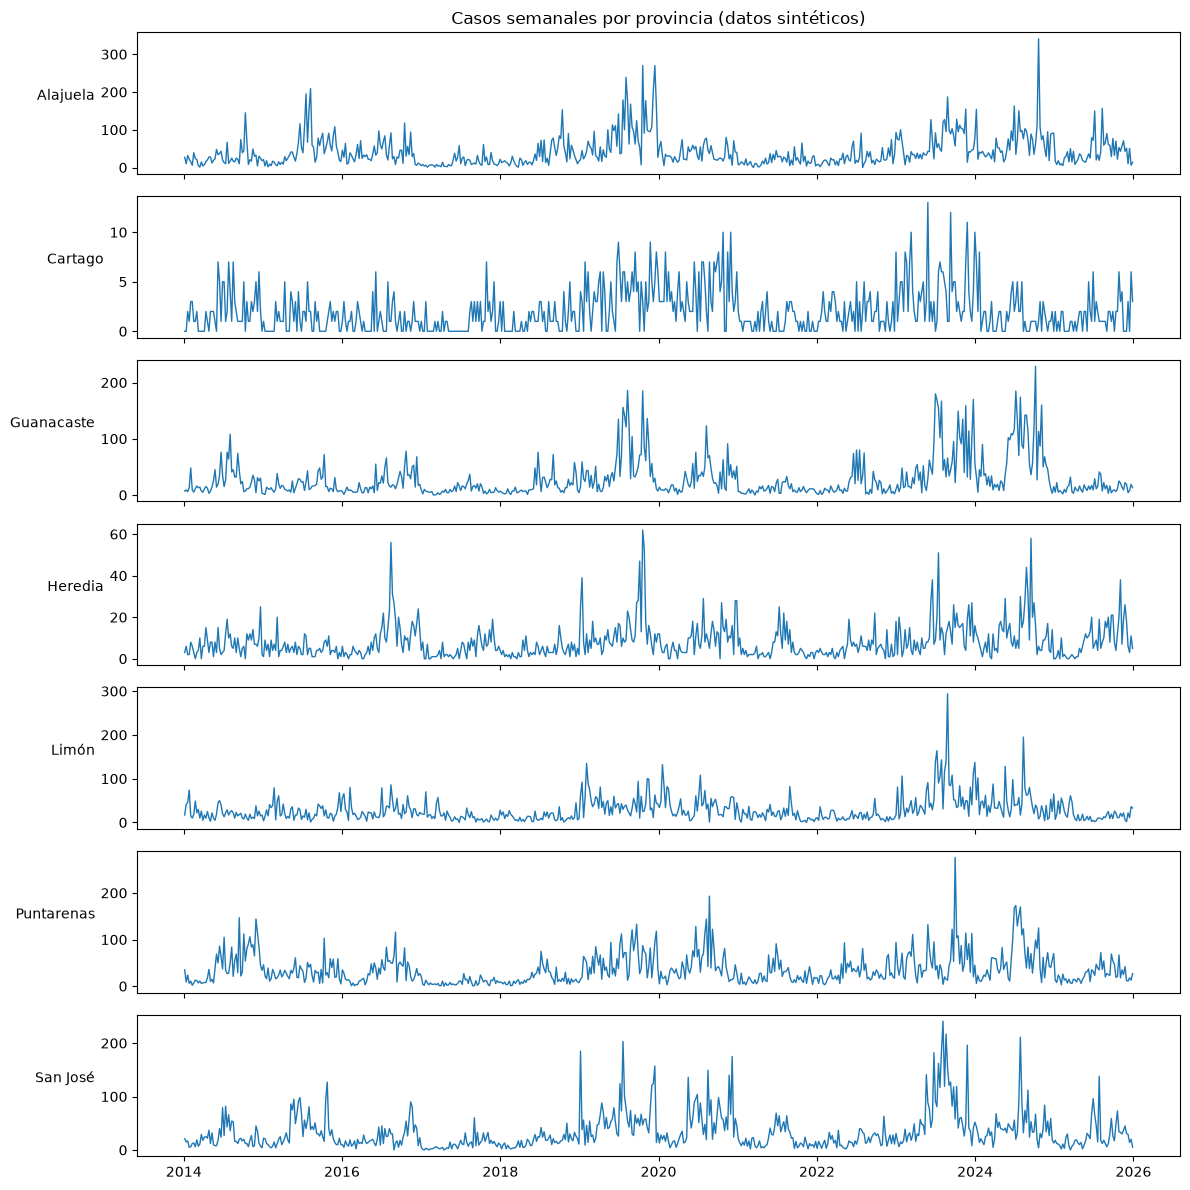

In [4]:
fig, ejes = plt.subplots(len(provincias), 1, figsize=(12, 12), sharex=True)
for eje, provincia in zip(ejes, provincias):
    grupo = df[df["provincia"] == provincia]
    eje.plot(grupo["fecha_inicio_semana"], grupo["casos_dengue"], linewidth=1)
    eje.set_ylabel(provincia, rotation=0, ha="right")
ejes[0].set_title("Casos semanales por provincia (datos sintéticos)")
plt.tight_layout()
plt.show()

- Las provincias tienen niveles muy distintos: Alajuela, San José, Puntarenas, Guanacaste y Limón tienen muchos más casos que Heredia, y Cartago casi no tiene (por su altitud). Por eso, igual que en el notebook 03, entrenamos con `log_casos`.
- Los brotes de 2019 y 2023 se ven en todas las provincias, y el de 2024 en casi todas (en Cartago no). 2017 es un año bajo en casi todas.
- Como hay un solo modelo para las 7 provincias, le agregamos **qué provincia es** como columnas *one-hot*: una columna por provincia, con 1 en la suya y 0 en las demás. En la sección 8.1 revisamos con validación si eso ayuda.

In [5]:
df["semana_sin"] = np.sin(2 * np.pi * df["semana_epi"] / 52)
df["semana_cos"] = np.cos(2 * np.pi * df["semana_epi"] / 52)

# One-hot de la provincia: prov_Alajuela, prov_Cartago, ...
provincia_one_hot = pd.get_dummies(df["provincia"], prefix="prov", dtype=float)
df = pd.concat([df, provincia_one_hot], axis=1)

clima = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
columnas_base = ["log_casos"] + clima + ["semana_sin", "semana_cos"]
columnas_con_provincia = columnas_base + list(provincia_one_hot.columns)
print(len(columnas_base), "variables base;", len(columnas_con_provincia), "con la provincia")

7 variables base; 14 con la provincia


# 4. Train/Test

El corte es temporal y es el mismo para las 7 provincias:

- **Test:** las últimas 104 semanas (2024-2025).
- **Validación:** las 52 semanas anteriores (2023). Sirve para EarlyStopping y para elegir variables (8.1).
- **Train:** todo lo anterior.

A diferencia del notebook 03, aquí el año de validación (2023) sí tiene brote, así que EarlyStopping no premia solo los pronósticos suaves.

In [6]:
SEMANAS_TEST = 104
SEMANAS_VALIDACION = 52

fechas = df.loc[df["provincia"] == provincias[0], "fecha_inicio_semana"].reset_index(drop=True)
n_semanas = len(fechas)    # las 7 provincias tienen las mismas semanas
inicio_test = n_semanas - SEMANAS_TEST
inicio_validacion = inicio_test - SEMANAS_VALIDACION

print("Train: hasta", fechas[inicio_validacion - 1].date())
print("Validación:", fechas[inicio_validacion].date(), "a", fechas[inicio_test - 1].date())
print("Test:", fechas[inicio_test].date(), "a", fechas[n_semanas - 1].date())

Train: hasta 2023-01-01
Validación: 2023-01-08 a 2023-12-31
Test: 2024-01-07 a 2025-12-28


# 5. Escalado

In [7]:
from sklearn.preprocessing import MinMaxScaler

In [8]:
# Solo utilizamos datos anteriores al test para ajustar el escalado; si no, estaríamos usando información del test
antes_del_test = df["fecha_inicio_semana"] < fechas[inicio_test]

escalador_y = MinMaxScaler()
escalador_y.fit(df.loc[antes_del_test, ["log_casos"]].values)
df["y_escalado"] = escalador_y.transform(df[["log_casos"]].values).ravel()

# Casos de cada provincia, para armar los objetivos y los controles
casos_por_provincia = {p: df.loc[df["provincia"] == p, "casos_dengue"].values for p in provincias}

# 6. Ventanas de 26 semanas

En clase se usó `TimeseriesGenerator`, que corta **una** serie. Aquí hay 7, así que armamos las ventanas con un ciclo: para cada provincia y cada semana `i`, la entrada son las 26 semanas anteriores a `i` y el objetivo son las 4 semanas que empiezan en `i`. Al final se juntan las ventanas de las 7 provincias. Ninguna ventana mezcla dos provincias.

In [9]:
# Ventanas de las 7 provincias cuya primera semana pronosticada i va de "desde" a "hasta"
def crear_ventanas(columnas, escalador_X, desde, hasta):
    X, y, reales, info = [], [], [], []
    for provincia in provincias:
        grupo = df[df["provincia"] == provincia]
        valores = escalador_X.transform(grupo[columnas].values)
        objetivo = grupo["y_escalado"].values
        for i in range(max(desde, VENTANA), hasta + 1):
            X.append(valores[i - VENTANA:i])
            y.append(objetivo[i:i + HORIZONTE])
            reales.append(casos_por_provincia[provincia][i:i + HORIZONTE])
            info.append((provincia, i))
    return np.array(X), np.array(y), np.array(reales), pd.DataFrame(info, columns=["provincia", "fila"])


# Escala las columnas y crea las ventanas de train, validación y test
def preparar_datos(columnas):
    escalador_X = MinMaxScaler()
    escalador_X.fit(df.loc[antes_del_test, columnas].values)
    train = crear_ventanas(columnas, escalador_X, VENTANA, inicio_validacion - HORIZONTE)
    validacion = crear_ventanas(columnas, escalador_X, inicio_validacion, inicio_test - HORIZONTE)
    test = crear_ventanas(columnas, escalador_X, inicio_test, n_semanas - HORIZONTE)
    return escalador_X, train, validacion, test


# Pasa una predicción escalada a casos: quita el escalado y el logaritmo
def a_casos(prediccion_escalada):
    log_casos = escalador_y.inverse_transform(prediccion_escalada.reshape(-1, 1))
    return np.expm1(log_casos).reshape(-1, HORIZONTE).clip(min=0)

In [10]:
_, (X_ejemplo, y_ejemplo, _, _), (X_val_ejemplo, _, _, _), (X_test_ejemplo, _, _, _) = preparar_datos(columnas_con_provincia)
print("Entrada de train:", X_ejemplo.shape, "-> (ventanas, 26 semanas, variables)")
print("Objetivo de train:", y_ejemplo.shape, "-> (ventanas, 4 semanas)")
print("Ventanas de validación:", len(X_val_ejemplo), " Ventanas de test:", len(X_test_ejemplo), "(7 provincias)")

Entrada de train: (3087, 26, 14) -> (ventanas, 26 semanas, variables)
Objetivo de train: (3087, 4) -> (ventanas, 4 semanas)
Ventanas de validación: 343  Ventanas de test: 707 (7 provincias)


# 7. Creación del modelo

La misma red base del notebook 03, importada de `src/train/lstm.py`: **SimpleRNN(32) → Dense(4)**.

In [11]:
crear_simplernn(len(columnas_con_provincia)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,636 (6.39 KB)

 Trainable params: 1,636 (6.39 KB)

 Non-trainable params: 0 (0.00 B)

# 8. Entrenamiento del modelo

In [12]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [13]:
# Entrena una red con una semilla y devuelve también los datos preparados
def entrenar(columnas, semilla):
    tf.keras.utils.set_random_seed(semilla)
    escalador_X, train, validacion, test = preparar_datos(columnas)
    model = crear_simplernn(len(columnas))
    early_stop = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
    model.fit(train[0], train[1], epochs=200, batch_size=32,
              validation_data=(validacion[0], validacion[1]), callbacks=[early_stop], verbose=0)
    return model, escalador_X, validacion, test


def rmse(real, prediccion):
    return np.sqrt(mean_squared_error(real, prediccion))


def mae(real, prediccion):
    return mean_absolute_error(real, prediccion)

## 8.1 ¿Conviene decirle a la red qué provincia es?

Comparamos solo con validación, repitiendo con 3 semillas porque una red cambia de una corrida a otra.

In [14]:
resultados = []
for nombre, columnas in [("Sin provincia", columnas_base), ("Con provincia", columnas_con_provincia)]:
    for semilla in [101, 1, 2]:
        modelo, _, validacion, _ = entrenar(columnas, semilla)
        prediccion = a_casos(modelo.predict(validacion[0], verbose=0))
        resultados.append({"variables": nombre, "semilla": semilla, "RMSE_validacion": rmse(validacion[2], prediccion)})

comparacion = pd.DataFrame(resultados)
print(comparacion.pivot(index="semilla", columns="variables", values="RMSE_validacion").round(2))
print(comparacion.groupby("variables")["RMSE_validacion"].mean().round(2))

variables  Con provincia  Sin provincia
semilla                                
1                  38.86          40.90
2                  41.61          41.34
101                41.12          39.98
variables
Con provincia    40.53
Sin provincia    40.74
Name: RMSE_validacion, dtype: float64


**Resultado:** prácticamente un empate (40.5 con la provincia contra 40.7 sin ella). La diferencia es menor que la que hay entre una semilla y otra, así que saber la provincia casi no ayuda: los casos en logaritmo ya le dicen a la red en qué nivel está cada provincia. Se queda la versión con provincia porque tuvo el menor promedio, que es la regla que fijamos antes de entrenar.

## 8.2 Entrenamiento del modelo final

In [15]:
promedios = comparacion.groupby("variables")["RMSE_validacion"].mean()
columnas_finales = columnas_con_provincia if promedios["Con provincia"] <= promedios["Sin provincia"] else columnas_base
print("Variables elegidas:", columnas_finales)

Variables elegidas: ['log_casos', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct', 'semana_sin', 'semana_cos', 'prov_Alajuela', 'prov_Cartago', 'prov_Guanacaste', 'prov_Heredia', 'prov_Limón', 'prov_Puntarenas', 'prov_San José']


In [16]:
tf.keras.utils.set_random_seed(101)   # la misma semilla del notebook 03
escalador_X, train, validacion, test = preparar_datos(columnas_finales)
X_test, y_test, real_test, info_test = test

modelo_provincias = crear_simplernn(len(columnas_finales))
early_stop = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
modelo_provincias.fit(train[0], train[1], epochs=200, batch_size=32,
                      validation_data=(validacion[0], validacion[1]),
                      callbacks=[early_stop], verbose=0)

Épocas entrenadas: 47 | mejor época (la que se guarda): 27


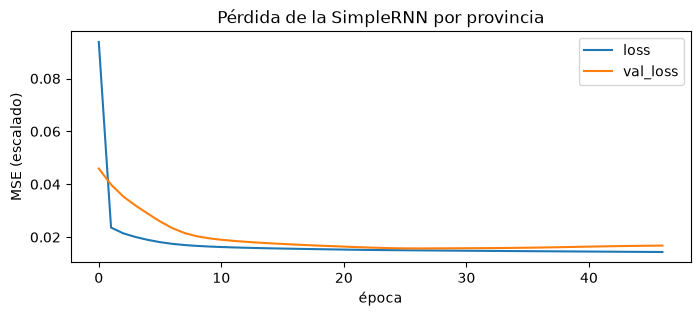

In [17]:
losses = pd.DataFrame(modelo_provincias.history.history)
print("Épocas entrenadas:", len(losses), "| mejor época (la que se guarda):", int(losses["val_loss"].idxmin()) + 1)

losses.plot(figsize=(8, 3), title="Pérdida de la SimpleRNN por provincia")
plt.xlabel("época")
plt.ylabel("MSE (escalado)")
plt.show()

# 9. Evaluación del modelo

Medimos en **casos**, no en logaritmo, sobre las 101 ventanas completas del test de cada provincia (707 en total). Los controles son los mismos del notebook 03:

- **Baseline estacional (lo pide el enunciado):** la misma semana del año anterior.
- **Persistencia:** las próximas 4 semanas repiten los casos de la última semana conocida.

In [18]:
prediccion_test = a_casos(modelo_provincias.predict(X_test, verbose=0))

estacional = np.array([casos_por_provincia[p][i - 52:i - 52 + HORIZONTE] for p, i in info_test.itertuples(index=False)])
persistencia = np.array([[casos_por_provincia[p][i - 1]] * HORIZONTE for p, i in info_test.itertuples(index=False)])

pronosticos = {"SimpleRNN": prediccion_test, "Baseline estacional": estacional, "Persistencia": persistencia}
tabla = pd.DataFrame({
    "RMSE": [rmse(real_test, p) for p in pronosticos.values()],
    "MAE": [mae(real_test, p) for p in pronosticos.values()],
}, index=pronosticos.keys()).round(1)
print(tabla)

print("Mejora de la SimpleRNN sobre el baseline estacional (%):")
print((100 * (1 - tabla.loc["SimpleRNN"] / tabla.loc["Baseline estacional"])).round(1))

                     RMSE   MAE
SimpleRNN            27.8  15.4
Baseline estacional  49.0  30.5
Persistencia         35.3  19.9
Mejora de la SimpleRNN sobre el baseline estacional (%):
RMSE    43.3
MAE     49.5
dtype: float64


In [19]:
# Error por provincia: cada provincia tiene su propio nivel de casos
filas = []
for provincia in provincias:
    m = (info_test["provincia"] == provincia).values
    filas.append({
        "provincia": provincia,
        "casos_promedio": real_test[m].mean(),
        "RMSE_SimpleRNN": rmse(real_test[m], prediccion_test[m]),
        "RMSE_estacional": rmse(real_test[m], estacional[m]),
        "RMSE_persistencia": rmse(real_test[m], persistencia[m]),
        "MAE_SimpleRNN": mae(real_test[m], prediccion_test[m]),
        "MAE_estacional": mae(real_test[m], estacional[m]),
        "MAE_persistencia": mae(real_test[m], persistencia[m]),
    })
por_provincia = pd.DataFrame(filas).set_index("provincia")
por_provincia["mejora_vs_estacional_%"] = 100 * (1 - por_provincia["RMSE_SimpleRNN"] / por_provincia["RMSE_estacional"])
por_provincia.round(1)

,casos_promedio,RMSE_SimpleRNN,RMSE_estacional,RMSE_persistencia,MAE_SimpleRNN,MAE_estacional,MAE_persistencia,mejora_vs_estacional_%
provincia,,,,,,,,
Alajuela,54.7,42.1,59.2,56.5,26.5,39.2,35.4,28.8
Cartago,1.5,1.6,3.4,2.2,1.2,2.4,1.5,52.2
Guanacaste,40.0,34.7,65.7,39.5,20.2,47.7,24.1,47.3
Heredia,10.7,9.0,13.5,10.9,6.0,9.5,7.8,33.7
Limón,30.6,26.3,51.8,35.2,16.0,35.5,22.7,49.2
Puntarenas,43.4,30.1,60.0,34.9,20.8,44.7,24.4,49.7
San José,34.8,27.4,49.7,37.1,16.9,34.9,23.5,44.9


In [20]:
# Error según qué tan lejos es el pronóstico
pd.DataFrame({
    "RMSE_SimpleRNN": [rmse(real_test[:, h], prediccion_test[:, h]) for h in range(HORIZONTE)],
    "RMSE_estacional": [rmse(real_test[:, h], estacional[:, h]) for h in range(HORIZONTE)],
    "RMSE_persistencia": [rmse(real_test[:, h], persistencia[:, h]) for h in range(HORIZONTE)],
}, index=[f"semana +{h + 1}" for h in range(HORIZONTE)]).round(1)

,RMSE_SimpleRNN,RMSE_estacional,RMSE_persistencia
semana +1,26.7,49.0,32.7
semana +2,27.8,48.9,34.9
semana +3,28.5,48.9,36.8
semana +4,28.2,49.0,36.6


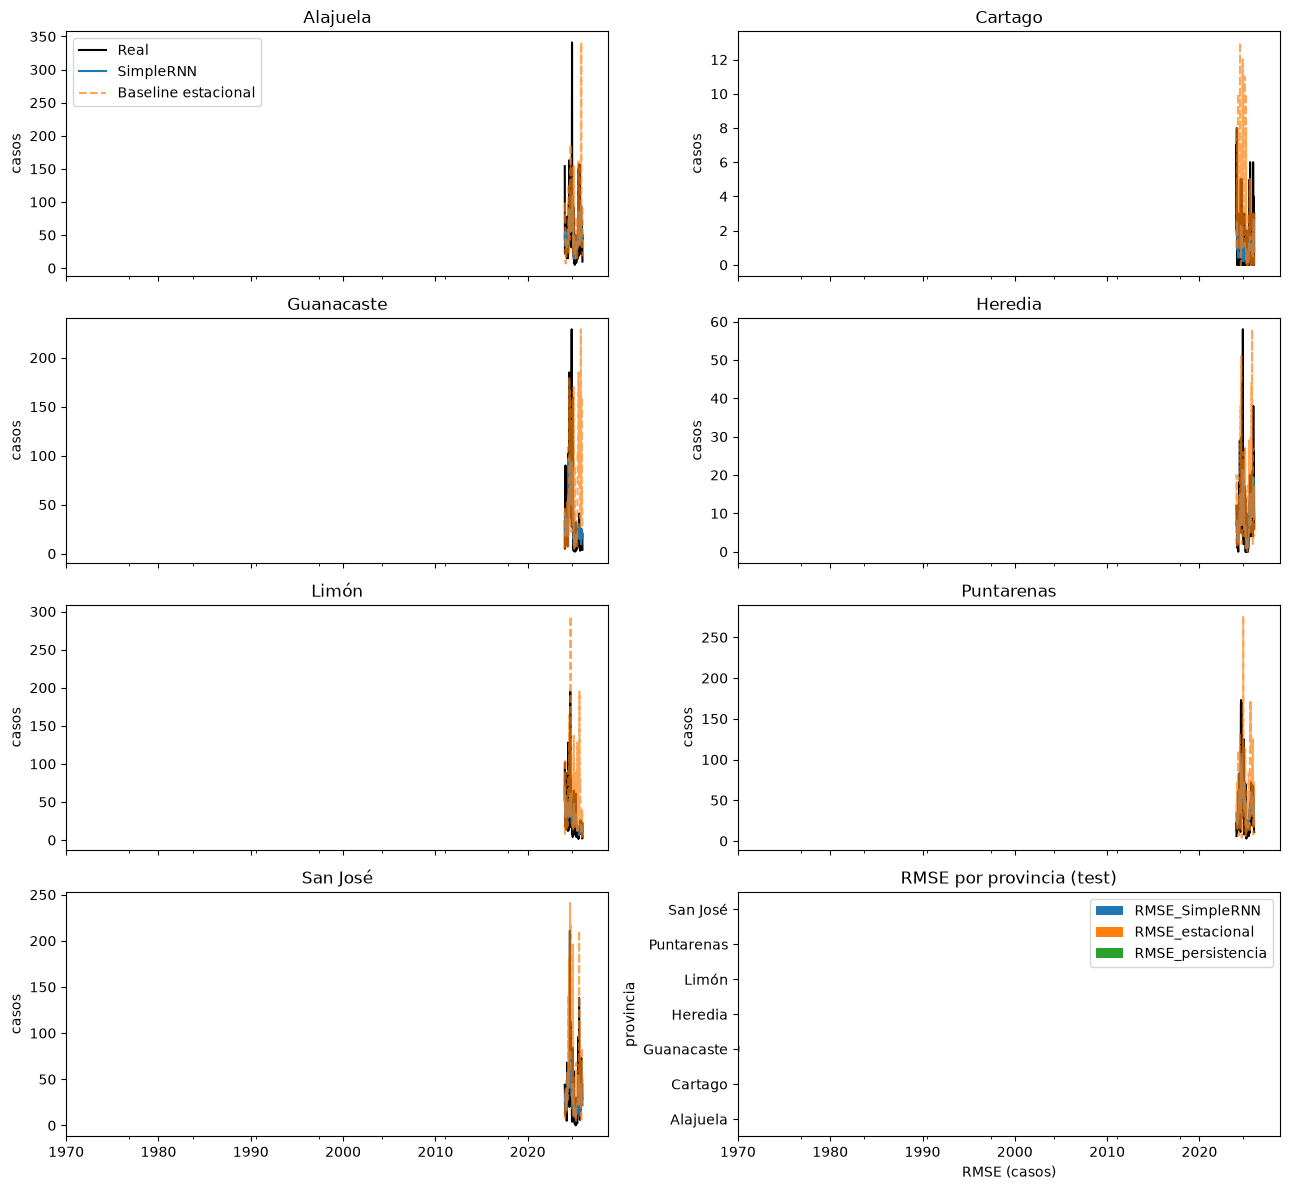

In [21]:
# Pronóstico a 1 semana contra lo real, en cada provincia
fig, ejes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
for eje, provincia in zip(ejes.ravel(), provincias):
    m = (info_test["provincia"] == provincia).values
    fechas_objetivo = fechas[info_test.loc[m, "fila"].values]
    eje.plot(fechas_objetivo, real_test[m, 0], label="Real", color="black")
    eje.plot(fechas_objetivo, prediccion_test[m, 0], label="SimpleRNN")
    eje.plot(fechas_objetivo, estacional[m, 0], label="Baseline estacional", linestyle="--", alpha=0.7)
    eje.set_title(provincia)
    eje.set_ylabel("casos")

# En el último espacio: RMSE por provincia
ultimo = ejes.ravel()[-1]
por_provincia[["RMSE_SimpleRNN", "RMSE_estacional", "RMSE_persistencia"]].plot.barh(ax=ultimo)
ultimo.set_title("RMSE por provincia (test)")
ultimo.set_xlabel("RMSE (casos)")
ejes.ravel()[0].legend()
plt.tight_layout()
plt.show()

## 9.1 ¿Qué tan estable es el resultado?

Repetimos el entrenamiento con 3 semillas. No se elige ninguna por su resultado en test: el modelo guardado es siempre el de la semilla 101.

In [22]:
semillas = []
for semilla in [101, 1, 2]:
    modelo, _, _, test_semilla = entrenar(columnas_finales, semilla)
    prediccion = a_casos(modelo.predict(test_semilla[0], verbose=0))
    semillas.append({"semilla": semilla, "RMSE": rmse(real_test, prediccion), "MAE": mae(real_test, prediccion)})

estabilidad = pd.DataFrame(semillas).set_index("semilla")
print(estabilidad.round(1))
print("Promedio:", estabilidad.mean().round(1).to_dict())

         RMSE   MAE
semilla            
101      27.8  15.4
1        27.2  15.0
2        27.8  15.2
Promedio: {'RMSE': 27.6, 'MAE': 15.2}


## 9.2 Guardar el modelo

Se guarda con el mismo formato que el notebook 03, más la lista de provincias. Los resultados del test se guardan **calculados** en un JSON para que la API los muestre sin escribirlos a mano.

In [23]:
os.makedirs("../models", exist_ok=True)
modelo_provincias.save("../models/rnn_provincias.h5")

joblib.dump({"columnas": columnas_finales, "provincias": provincias,
             "escalador_X": escalador_X, "escalador_y": escalador_y,
             "ventana": VENTANA, "horizonte": HORIZONTE, "datos": "sinteticos"},
            "../models/rnn_provincias_preprocesado.pkl")

resultados_json = {
    "datos": "sinteticos (vectoria_dengue_semanal.csv, limpiado en el EDA)",
    "modelo": "rnn_provincias.h5",
    "variables": columnas_finales,
    "test": {"desde": str(fechas[inicio_test].date()), "hasta": str(fechas[n_semanas - 1].date()),
             "ventanas": int(len(X_test))},
    "global": {nombre: {"RMSE": round(float(fila.RMSE), 1), "MAE": round(float(fila.MAE), 1)}
               for nombre, fila in tabla.iterrows()},
    "por_provincia": {provincia: {columna: round(float(valor), 1) for columna, valor in fila.items()}
                      for provincia, fila in por_provincia.iterrows()},
}
with open("../models/rnn_provincias_resultados.json", "w", encoding="utf-8") as archivo:
    json.dump(resultados_json, archivo, ensure_ascii=False, indent=2)
print(sorted(os.listdir("../models")))

['.gitkeep', 'ann_acciones.keras', 'ann_acciones_preprocesado.pkl', 'ann_columns.pkl', 'ann_control.h5', 'cnn_mosquitos.keras', 'cnn_mosquitos_mejorada.keras', 'mobilenet_mosquitos.keras', 'mosquitos_clases.json', 'mosquitos_resultados.json', 'rnn_lstm.h5', 'rnn_lstm_preprocesado.pkl', 'rnn_provincias.h5', 'rnn_provincias_preprocesado.pkl', 'rnn_provincias_resultados.json', 'rnn_simple.h5', 'rnn_simple_preprocesado.pkl', 'scaler_ann.pkl']


## 9.3 Ejemplo de uso para la app

Cargamos todo desde disco, como lo hace la API (`/predict/casos/provincia`).

In [24]:
from tensorflow.keras.models import load_model

In [25]:
modelo = load_model("../models/rnn_provincias.h5", compile=False)
pre = joblib.load("../models/rnn_provincias_preprocesado.pkl")

# Las 26 semanas de Puntarenas antes de la última fecha que tiene sus 4 semanas reales
provincia = "Puntarenas"
grupo = df[df["provincia"] == provincia].reset_index(drop=True)
fin = n_semanas - HORIZONTE
semanas = grupo[pre["columnas"]].iloc[fin - pre["ventana"]:fin].values
entrada = pre["escalador_X"].transform(semanas)[np.newaxis, ...]

salida = modelo.predict(entrada, verbose=0)
pronostico = np.expm1(pre["escalador_y"].inverse_transform(salida.reshape(-1, 1))).ravel().clip(min=0)

print(provincia, "| pronóstico desde", grupo["fecha_inicio_semana"][fin].date(), ":", pronostico.round().astype(int))
print("Casos de esas semanas:", grupo["casos_dengue"].values[fin:fin + 4])

Puntarenas | pronóstico desde 2025-12-07 : [21 13 13 13]
Casos de esas semanas: [11 18 13 27]


# 10. Conclusiones

> Recordatorio: todo esto se midió con **datos sintéticos**.

- **Supera a los dos controles.** En test (707 ventanas, 2024-2025) la SimpleRNN tiene un RMSE de 27.8 y un MAE de 15.4, contra 49.0 y 30.5 del baseline estacional (43 % y 50 % menos) y 35.3 y 19.9 de la persistencia. A diferencia del modelo nacional del notebook 03, aquí **sí le gana a la persistencia**, en las 4 distancias (semana +1 a +4) y en las 7 provincias.
- **En cada provincia** mejora al baseline estacional entre 29 % (Alajuela) y 52 % (Cartago). Alajuela tiene el mayor RMSE (42.1) porque es la que tiene más casos (55 por semana en promedio en el test).
- **Es estable:** con 3 semillas, el RMSE va de 27.2 a 27.8.
- **Saber la provincia casi no cambió el resultado** (sección 8.1): 40.5 contra 40.7 en validación, menos que la diferencia entre semillas.
- **Por qué funciona mejor que con los datos reales:**
  - Hay más datos: 7 series dan 3,087 ventanas de entrenamiento, contra 381 del modelo nacional.
  - El año de validación (2023) tuvo brote, así que EarlyStopping no premia los pronósticos suaves.
  - Los datos sintéticos siguen patrones regulares que puso el generador (según `LEEME_datos.md`, la lluvia actúa con unas 4 semanas de rezago y el pico es en julio y agosto). Los datos reales son más irregulares.
- **Límite principal:** como los datos son sintéticos, esto muestra que el método y el código funcionan, no que la red pronostique el dengue real de cada provincia. El mismo notebook serviría con datos reales por provincia (por ejemplo, de los boletines del Ministerio de Salud), que no venían en el paquete del curso.

El modelo se usa en la API (`POST /predict/casos/provincia` y los gráficos de `/visual/provincias`) y en la pestaña de pronóstico de la app.